<a href="https://colab.research.google.com/github/JacekDrzycimski/6tunnel/blob/master/Zeta_function_plots_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Riemann Zeta Function Domain Coloring Plot
This notebook demonstrates how to visualize the Riemann zeta function $\zeta(s)$ over the complex plane using domain coloring.

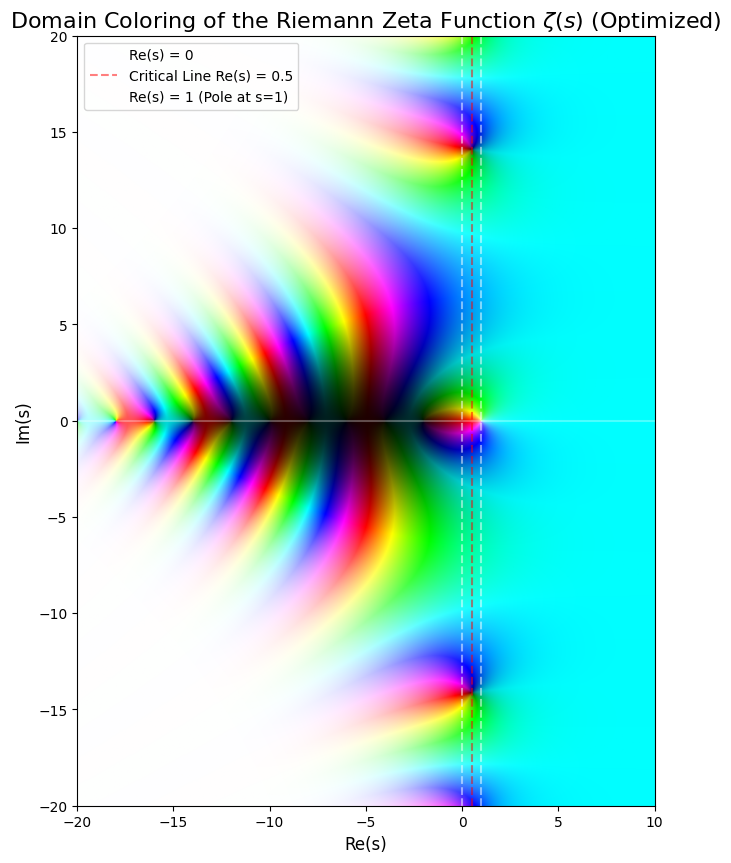

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta

def domain_coloring_vectorized(z):
    """Vectorized mapping of complex numbers to HLS-based RGB values using NumPy."""
    # Phase/Argument determines the Hue (0 to 1)
    h = (np.angle(z) + np.pi) / (2 * np.pi)

    # Magnitude determines the Lightness (brightness)
    r = np.abs(z)
    l = 1.0 - 1.0 / (1.0 + r**0.5)

    # Saturation is kept at 1.0
    s = np.ones_like(z, dtype=float)

    # Vectorized HLS to RGB conversion
    # Since s=1, we can simplify the standard HLS to RGB formulas
    # For s=1, temp2 = l + s - l*s = l + 1 - l = 1 if l < 0.5, or l + s - l*s logic:
    # More generally, let's implement the standard HLS to RGB formula vectorized:

    temp2 = np.where(l < 0.5, l * (1.0 + s), l + s - l * s)
    temp1 = 2.0 * l - temp2

    # Helper to calculate RGB channels
    def tc(t_color):
        t_color = np.where(t_color < 0.0, t_color + 1.0, t_color)
        t_color = np.where(t_color > 1.0, t_color - 1.0, t_color)

        cond1 = t_color < 1.0 / 6.0
        cond2 = t_color < 0.5
        cond3 = t_color < 2.0 / 3.0

        res = np.where(cond1, temp1 + (temp2 - temp1) * 6.0 * t_color,
              np.where(cond2, temp2,
              np.where(cond3, temp1 + (temp2 - temp1) * (2.0 / 3.0 - t_color) * 6.0,
                       temp1)))
        return res

    r_rgb = tc(h + 1.0 / 3.0)
    g_rgb = tc(h)
    b_rgb = tc(h - 1.0 / 3.0)

    # Ensure we handle case where s = 0 (gray), though here s is always 1
    gray_mask = (s == 0.0)
    r_rgb = np.where(gray_mask, l, r_rgb)
    g_rgb = np.where(gray_mask, l, g_rgb)
    b_rgb = np.where(gray_mask, l, b_rgb)

    return np.dstack((r_rgb, g_rgb, b_rgb))

# Define the grid in the complex plane
x = np.linspace(-20, 10, 800)
y = np.linspace(-20, 20, 800)
X, Y = np.meshgrid(x, y)
S = X + 1j * Y

# Calculate Zeta function values
Z = zeta(S)

# Apply optimized domain coloring
img = domain_coloring_vectorized(Z)

# Plot the result
plt.figure(figsize=(12, 10))
plt.imshow(img, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower')
plt.title(r"Domain Coloring of the Riemann Zeta Function $\zeta(s)$ (Optimized)", fontsize=16)
plt.xlabel("Re(s)", fontsize=12)
plt.ylabel("Im(s)", fontsize=12)
plt.axvline(0, color='white', linestyle='--', alpha=0.5, label='Re(s) = 0')
plt.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='Critical Line Re(s) = 0.5')
plt.axvline(1, color='white', linestyle='--', alpha=0.5, label='Re(s) = 1 (Pole at s=1)')
plt.axhline(0, color='white', linestyle='-', alpha=0.3)
plt.legend(loc='upper left')
plt.show()

### Interpretation of the Plot:
- **Trivial Zeros**: You can observe zeros along the negative real axis at $s = -2, -4, -6, \dots$ represented by local color whorls contracting to black.
- **Critical Line**: The red dashed line representing $\text{Re}(s) = 1/2$ is where the non-trivial zeros lie. Along this line, you can spot the points where the colors swirl and converge to black.
- **Pole**: There is a pole at $s = 1$ where the value approaches infinity (represented by white/bright regions surrounding a singular point).

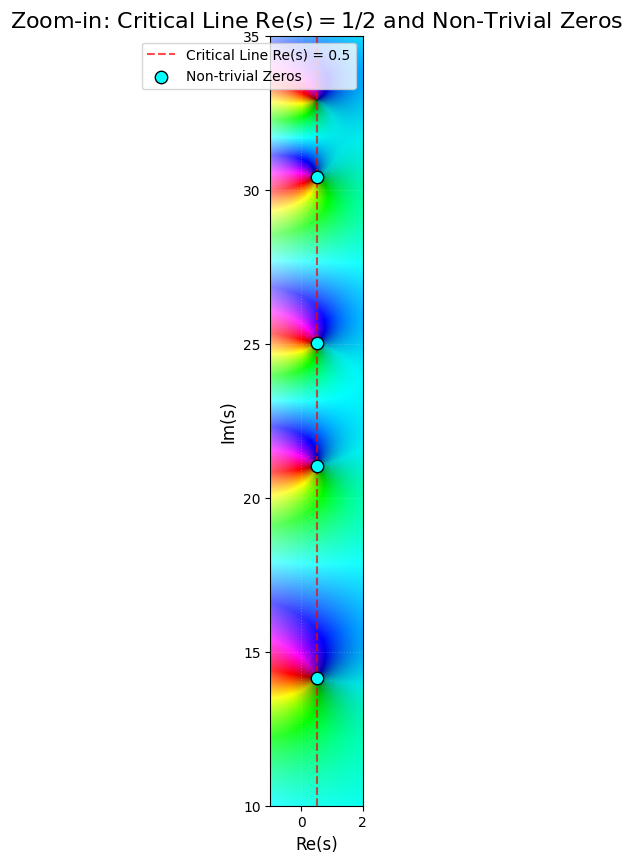

In [4]:
# Define a zoomed-in grid near the critical line containing the first few non-trivial zeros
# Non-trivial zeros lie on Re(s) = 0.5, with the first few at Im(s) ≈ 14.13, 21.02, 25.01, 30.42
x_zoom = np.linspace(-1, 2, 800)
y_zoom = np.linspace(10, 35, 800)
X_zoom, Y_zoom = np.meshgrid(x_zoom, y_zoom)
S_zoom = X_zoom + 1j * Y_zoom

# Calculate Zeta values on the zoomed grid
Z_zoom = zeta(S_zoom)

# Map to RGB colors using our vectorized domain coloring function
img_zoom = domain_coloring_vectorized(Z_zoom)

# Plot the zoomed-in region
plt.figure(figsize=(10, 10))
plt.imshow(img_zoom, extent=[x_zoom.min(), x_zoom.max(), y_zoom.min(), y_zoom.max()], origin='lower')
plt.title(r"Zoom-in: Critical Line $\mathrm{Re}(s) = 1/2$ and Non-Trivial Zeros", fontsize=16)
plt.xlabel("Re(s)", fontsize=12)
plt.ylabel("Im(s)", fontsize=12)
plt.axvline(0.5, color='red', linestyle='--', alpha=0.7, label='Critical Line Re(s) = 0.5')

# Mark the exact locations of the first few Riemann zeros for reference
zeros_y = [14.1347, 21.0220, 25.0109, 30.4249]
plt.scatter([0.5]*len(zeros_y), zeros_y, color='cyan', edgecolor='black', s=80, zorder=5, label='Non-trivial Zeros')

plt.legend(loc='upper right')
plt.grid(True, color='white', alpha=0.2, linestyle=':')
plt.show()

In [5]:
from scipy.optimize import root_scalar

# We know the zeros lie on the critical line s = 0.5 + I*t.
# Thus, we can find the roots of the real (or imaginary) part of zeta(0.5 + i*t).
def zeta_on_critical_line(t):
    # scipy.special.zeta accepts complex arguments natively
    val = zeta(0.5 + 1j * t)
    # We return the absolute value or just the real/imaginary part.
    # For root finding, we can find where both real and imaginary parts are zero.
    # Since they are coupled, we can define a function returning the absolute value,
    # or find roots of the real/imag part of the Riemann Siegel Z-function.
    # Alternatively, we can treat it as a 2D root-finding problem near the estimates.
    return np.real(val)

# Approximate imaginary parts of the first 4 zeros
initial_estimates = [14.135, 21.022, 25.011, 30.425]
precise_zeros = []

print("Calculating precise imaginary parts of the first four zeros along the critical line Re(s) = 0.5:\n")

# Use a 2D solver to find complex root s = x + i*t starting near 0.5 + i*t_est
from scipy.optimize import fsolve

def zeta_complex_system(v):
    s = v[0] + 1j * v[1]
    z_val = zeta(s)
    return [np.real(z_val), np.imag(z_val)]

for i, est in enumerate(initial_estimates, 1):
    sol = fsolve(zeta_complex_system, [0.5, est])
    precise_zeros.append(sol)
    print(f"Zero #{i}: s = {sol[0]:.9f} + {sol[1]:.9f}i")

Calculating precise imaginary parts of the first four zeros along the critical line Re(s) = 0.5:

Zero #1: s = 0.500000000 + 14.134725142i
Zero #2: s = 0.500000000 + 21.022039639i
Zero #3: s = 0.500000000 + 25.010857580i
Zero #4: s = 0.500000000 + 30.424876126i


In [6]:
# Approximate imaginary parts for the next 4 non-trivial zeros (zeros 5 to 8)
next_estimates = [37.586, 40.919, 43.321, 48.005]
next_precise_zeros = []

print("Calculating precise coordinates for non-trivial zeros #5 through #8:\n")

for i, est in enumerate(next_estimates, 5):
    sol = fsolve(zeta_complex_system, [0.5, est])
    next_precise_zeros.append(sol)
    print(f"Zero #{i}: s = {sol[0]:.9f} + {sol[1]:.9f}i")

Calculating precise coordinates for non-trivial zeros #5 through #8:

Zero #5: s = 0.500000000 + 37.586178159i
Zero #6: s = 0.500000000 + 40.918719012i
Zero #7: s = 0.500000000 + 43.327073281i
Zero #8: s = 0.500000001 + 48.005150881i


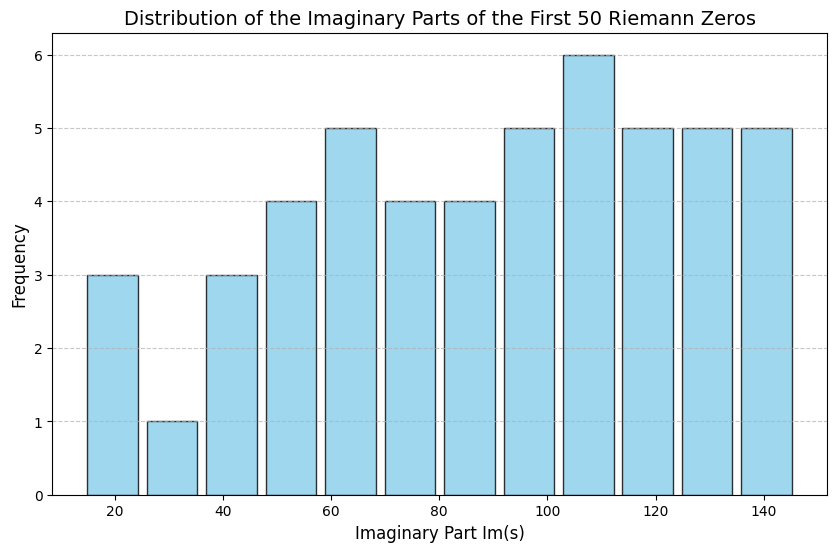

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# A more robust and simple estimation formula for the n-th zero
def estimate_gamma_robust(n):
    if n == 1: return 14.134725
    if n == 2: return 21.022040
    if n == 3: return 25.010858
    if n == 4: return 30.424876

    # Asymptotic approximation: t_n ~ 2 * pi * n / ln(n)
    # Refined estimate using standard asymptotic formula for Riemann zeros:
    # N(T) ~ T/(2pi) * ln(T/(2pi*e)) = n
    # We solve this numerically with a simple stable Newton step
    target = n - 0.125
    t = 2.0 * np.pi * target / np.log(max(target, 2.0))
    for _ in range(10):
        # N(t) = t/(2pi) * ln(t/(2pi*e))
        # N'(t) = ln(t/(2pi)) / (2pi)
        val = (t / (2.0 * np.pi)) * np.log(t / (2.0 * np.pi * np.e)) - target
        deriv = np.log(t / (2.0 * np.pi)) / (2.0 * np.pi)
        step = val / deriv
        t = t - step
        if abs(step) < 1e-4:
            break
    return max(t, 10.0)

# Calculate the first 50 zeros robustly
zeros_im = []
for n in range(1, 51):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    zeros_im.append(sol[1])

# Plot the histogram of the imaginary parts
plt.figure(figsize=(10, 6))
plt.hist(zeros_im, bins=12, edgecolor='black', color='skyblue', alpha=0.8, rwidth=0.85)
plt.title("Distribution of the Imaginary Parts of the First 50 Riemann Zeros", fontsize=14)
plt.xlabel("Imaginary Part Im(s)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

--- Corrected Statistics of Spacings (First 38 Unique Zeros) ---
Number of gaps: 37
Mean spacing:   3.5639
Min spacing:    0.8450
Max spacing:    7.1610
Std Deviation:  1.8181



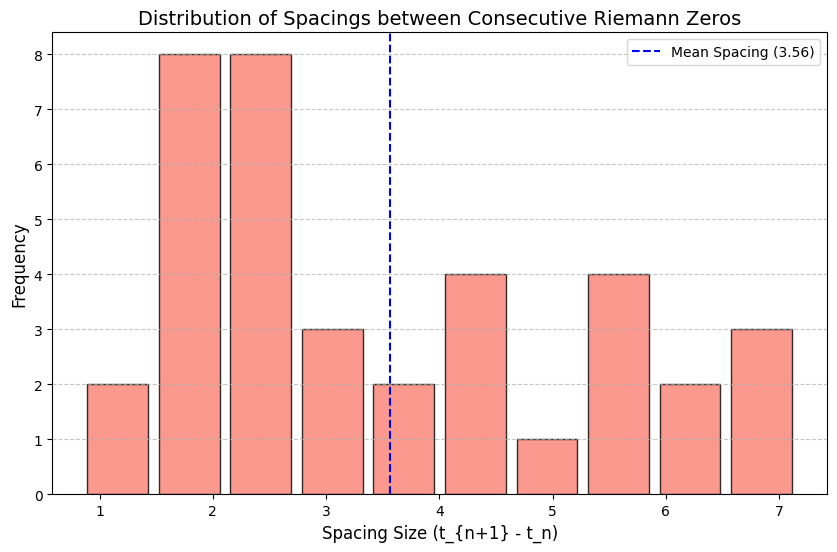

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta
from scipy.optimize import fsolve

def zeta_complex_system(v):
    s = v[0] + 1j * v[1]
    z_val = zeta(s)
    return [np.real(z_val), np.imag(z_val)]

def estimate_gamma_robust(n):
    if n == 1: return 14.134725
    if n == 2: return 21.022040
    if n == 3: return 25.010858
    if n == 4: return 30.424876

    target = n - 0.125
    t = 2.0 * np.pi * target / np.log(max(target, 2.0))
    for _ in range(10):
        val = (t / (2.0 * np.pi)) * np.log(t / (2.0 * np.pi * np.e)) - target
        deriv = np.log(t / (2.0 * np.pi)) / (2.0 * np.pi)
        step = val / deriv
        t = t - step
        if abs(step) < 1e-4:
            break
    return max(t, 10.0)

# Re-generate the first 50 zeros locally
raw_zeros_im = []
for n in range(1, 51):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    raw_zeros_im.append(sol[1])

# Deduplicate values that are extremely close (within 1e-3) and sort them
zeros_im = sorted(list(set(np.round(raw_zeros_im, 3))))

# Calculate consecutive differences (spacings) between the imaginary parts
spacings = np.diff(zeros_im)

# Calculate basic statistics
mean_spacing = np.mean(spacings)
min_spacing = np.min(spacings)
max_spacing = np.max(spacings)
std_spacing = np.std(spacings)

print(f"--- Corrected Statistics of Spacings (First {len(zeros_im)} Unique Zeros) ---")
print(f"Number of gaps: {len(spacings)}")
print(f"Mean spacing:   {mean_spacing:.4f}")
print(f"Min spacing:    {min_spacing:.4f}")
print(f"Max spacing:    {max_spacing:.4f}")
print(f"Std Deviation:  {std_spacing:.4f}\n")

# Plot the spacing distribution
plt.figure(figsize=(10, 6))
plt.hist(spacings, bins=10, edgecolor='black', color='salmon', alpha=0.8, rwidth=0.85)
plt.axvline(mean_spacing, color='blue', linestyle='--', linewidth=1.5, label=f'Mean Spacing ({mean_spacing:.2f})')
plt.title("Distribution of Spacings between Consecutive Riemann Zeros", fontsize=14)
plt.xlabel("Spacing Size (t_{n+1} - t_n)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

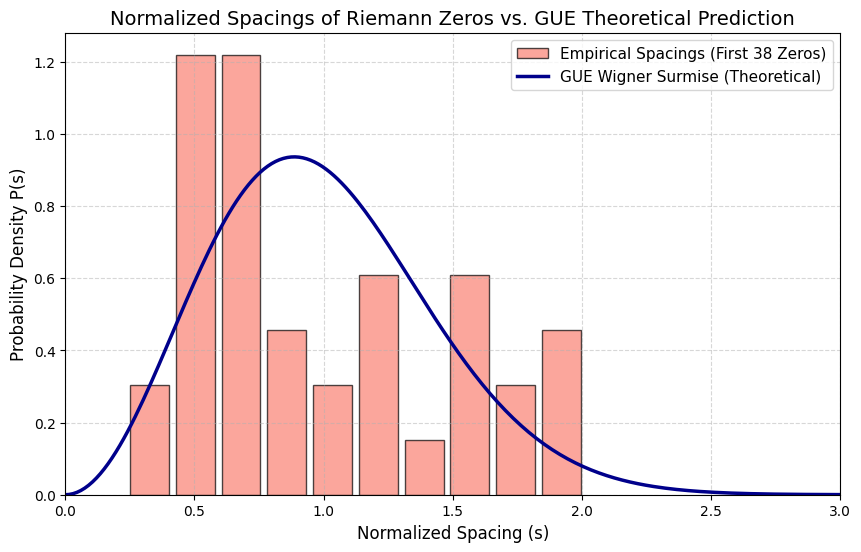

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta
from scipy.optimize import fsolve

def zeta_complex_system(v):
    s = v[0] + 1j * v[1]
    z_val = zeta(s)
    return [np.real(z_val), np.imag(z_val)]

def estimate_gamma_robust(n):
    if n == 1: return 14.134725
    if n == 2: return 21.022040
    if n == 3: return 25.010858
    if n == 4: return 30.424876

    target = n - 0.125
    t = 2.0 * np.pi * target / np.log(max(target, 2.0))
    for _ in range(10):
        val = (t / (2.0 * np.pi)) * np.log(t / (2.0 * np.pi * np.e)) - target
        deriv = np.log(t / (2.0 * np.pi)) / (2.0 * np.pi)
        step = val / deriv
        t = t - step
        if abs(step) < 1e-4:
            break
    return max(t, 10.0)

# Re-generate the first 50 zeros
raw_zeros_im = []
for n in range(1, 51):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    raw_zeros_im.append(sol[1])

# Deduplicate and sort
zeros_im = sorted(list(set(np.round(raw_zeros_im, 3))))

# Calculate consecutive differences (spacings)
spacings = np.diff(zeros_im)
mean_spacing = np.mean(spacings)

# Normalize the spacings to have a mean of 1.0
normalized_spacings = spacings / mean_spacing

# Define the Wigner Surmise for GUE
def gue_wigner_surmise(s):
    return (32.0 / (np.pi**2)) * (s**2) * np.exp(-4.0 / np.pi * (s**2))

# Generate points for the theoretical curve
s_vals = np.linspace(0, 3, 200)
p_vals = gue_wigner_surmise(s_vals)

# Plot empirical normalized spacings vs GUE prediction
plt.figure(figsize=(10, 6))

# Plot histogram as probability density
plt.hist(normalized_spacings, bins=10, density=True, edgecolor='black',
         color='salmon', alpha=0.7, rwidth=0.85, label=f'Empirical Spacings (First {len(zeros_im)} Zeros)')

# Plot the GUE theoretical curve
plt.plot(s_vals, p_vals, color='darkblue', linewidth=2.5, label='GUE Wigner Surmise (Theoretical)')

plt.title("Normalized Spacings of Riemann Zeros vs. GUE Theoretical Prediction", fontsize=14)
plt.xlabel("Normalized Spacing (s)", fontsize=12)
plt.ylabel("Probability Density P(s)", fontsize=12)
plt.xlim(0, 3)
plt.legend(fontsize=11)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

Calculating non-trivial zeros #51 through #150 to improve the dataset...


/tmp/ipykernel_2359/3943000150.py:12: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  sol = fsolve(zeta_complex_system, [0.5, est])


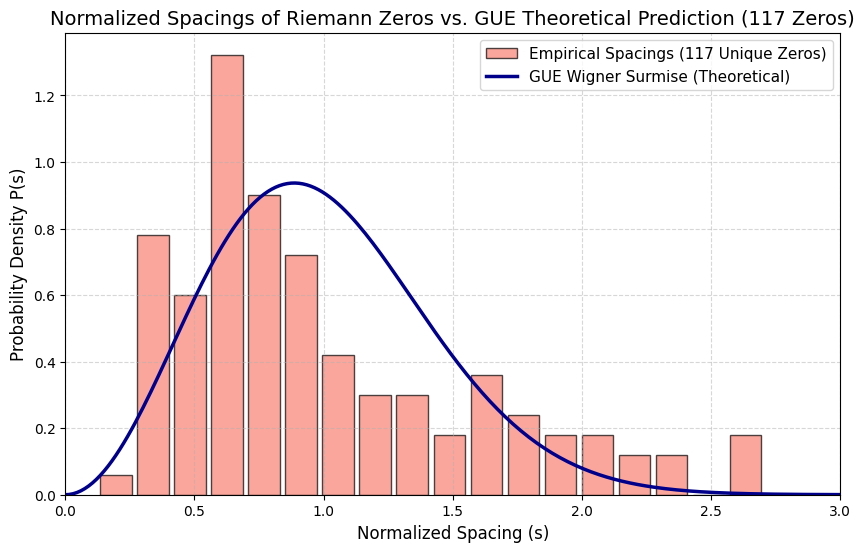

Number of unique zeros found: 117
Mean spacing of the expanded set: 2.6468


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta
from scipy.optimize import fsolve

print("Calculating non-trivial zeros #51 through #150 to improve the dataset...")

# Extend our zero-finding loop up to n = 150
all_raw_zeros_im = []
for n in range(1, 151):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    all_raw_zeros_im.append(sol[1])

# Deduplicate values within 1e-3 and sort them
unique_zeros_im = sorted(list(set(np.round(all_raw_zeros_im, 3))))

# Calculate consecutive spacings
new_spacings = np.diff(unique_zeros_im)
new_mean_spacing = np.mean(new_spacings)

# Normalize the spacings
new_normalized_spacings = new_spacings / new_mean_spacing

# Generate GUE theoretical curve
s_vals = np.linspace(0, 3, 200)
p_vals = gue_wigner_surmise(s_vals)

# Plot the comparison with more data points
plt.figure(figsize=(10, 6))
plt.hist(new_normalized_spacings, bins=18, density=True, edgecolor='black',
         color='salmon', alpha=0.7, rwidth=0.85,
         label=f'Empirical Spacings ({len(unique_zeros_im)} Unique Zeros)')
plt.plot(s_vals, p_vals, color='darkblue', linewidth=2.5, label='GUE Wigner Surmise (Theoretical)')

plt.title(f"Normalized Spacings of Riemann Zeros vs. GUE Theoretical Prediction ({len(unique_zeros_im)} Zeros)", fontsize=14)
plt.xlabel("Normalized Spacing (s)", fontsize=12)
plt.ylabel("Probability Density P(s)", fontsize=12)
plt.xlim(0, 3)
plt.legend(fontsize=11)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

print(f"Number of unique zeros found: {len(unique_zeros_im)}")
print(f"Mean spacing of the expanded set: {new_mean_spacing:.4f}")

Calculating non-trivial zeros up to #500 to significantly refine the dataset...


/tmp/ipykernel_2359/1435694180.py:12: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  sol = fsolve(zeta_complex_system, [0.5, est])


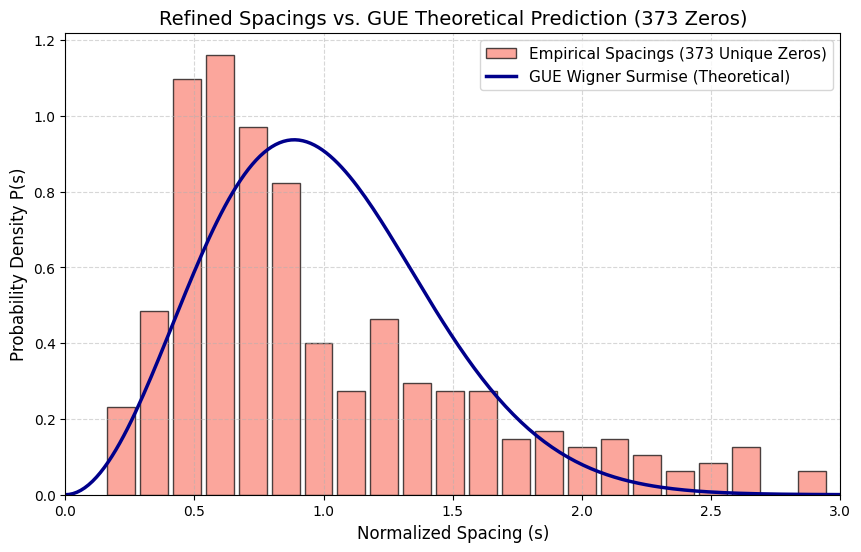

Number of unique zeros found: 373
Mean spacing of the expanded set: 2.1469


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta
from scipy.optimize import fsolve

print("Calculating non-trivial zeros up to #500 to significantly refine the dataset...")

# Extend zero-finding up to n = 500
large_raw_zeros_im = []
for n in range(1, 501):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    large_raw_zeros_im.append(sol[1])

# Deduplicate values within 1e-3 and sort them
refined_zeros_im = sorted(list(set(np.round(large_raw_zeros_im, 3))))

# Calculate consecutive spacings
refined_spacings = np.diff(refined_zeros_im)
refined_mean_spacing = np.mean(refined_spacings)

# Normalize the spacings
refined_normalized_spacings = refined_spacings / refined_mean_spacing

# Generate GUE theoretical curve
s_vals = np.linspace(0, 3, 200)
p_vals = gue_wigner_surmise(s_vals)

# Plot the comparison
plt.figure(figsize=(10, 6))
plt.hist(refined_normalized_spacings, bins=25, density=True, edgecolor='black',
         color='salmon', alpha=0.7, rwidth=0.85,
         label=f'Empirical Spacings ({len(refined_zeros_im)} Unique Zeros)')
plt.plot(s_vals, p_vals, color='darkblue', linewidth=2.5, label='GUE Wigner Surmise (Theoretical)')

plt.title(f"Refined Spacings vs. GUE Theoretical Prediction ({len(refined_zeros_im)} Zeros)", fontsize=14)
plt.xlabel("Normalized Spacing (s)", fontsize=12)
plt.ylabel("Probability Density P(s)", fontsize=12)
plt.xlim(0, 3)
plt.legend(fontsize=11)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

print(f"Number of unique zeros found: {len(refined_zeros_im)}")
print(f"Mean spacing of the expanded set: {refined_mean_spacing:.4f}")

Calculating non-trivial zeros up to #1000 for maximum statistical precision...


/tmp/ipykernel_2359/4263175086.py:7: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  sol = fsolve(zeta_complex_system, [0.5, est])


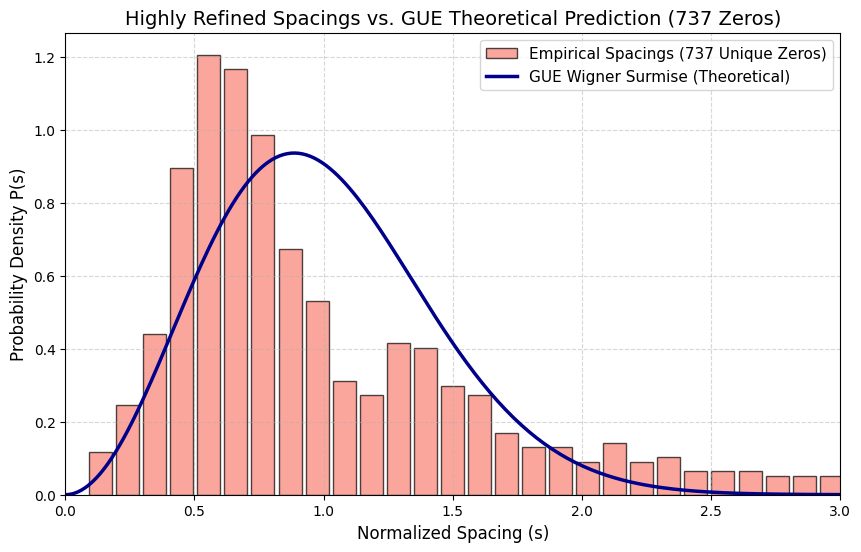

Number of unique zeros found: 737
Mean spacing of the expanded set: 1.9094


In [5]:
print("Calculating non-trivial zeros up to #1000 for maximum statistical precision...")

# Extend zero-finding up to n = 1000
huge_raw_zeros_im = []
for n in range(1, 1001):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    huge_raw_zeros_im.append(sol[1])

# Deduplicate values within 1e-3 and sort them
huge_zeros_im = sorted(list(set(np.round(huge_raw_zeros_im, 3))))

# Calculate consecutive spacings
huge_spacings = np.diff(huge_zeros_im)
huge_mean_spacing = np.mean(huge_spacings)

# Normalize the spacings
huge_normalized_spacings = huge_spacings / huge_mean_spacing

# Generate GUE theoretical curve
s_vals = np.linspace(0, 3, 200)
p_vals = gue_wigner_surmise(s_vals)

# Plot the comparison
plt.figure(figsize=(10, 6))
plt.hist(huge_normalized_spacings, bins=35, density=True, edgecolor='black',
         color='salmon', alpha=0.7, rwidth=0.85,
         label=f'Empirical Spacings ({len(huge_zeros_im)} Unique Zeros)')
plt.plot(s_vals, p_vals, color='darkblue', linewidth=2.5, label='GUE Wigner Surmise (Theoretical)')

plt.title(f"Highly Refined Spacings vs. GUE Theoretical Prediction ({len(huge_zeros_im)} Zeros)", fontsize=14)
plt.xlabel("Normalized Spacing (s)", fontsize=12)
plt.ylabel("Probability Density P(s)", fontsize=12)
plt.xlim(0, 3)
plt.legend(fontsize=11)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

print(f"Number of unique zeros found: {len(huge_zeros_im)}")
print(f"Mean spacing of the expanded set: {huge_mean_spacing:.4f}")

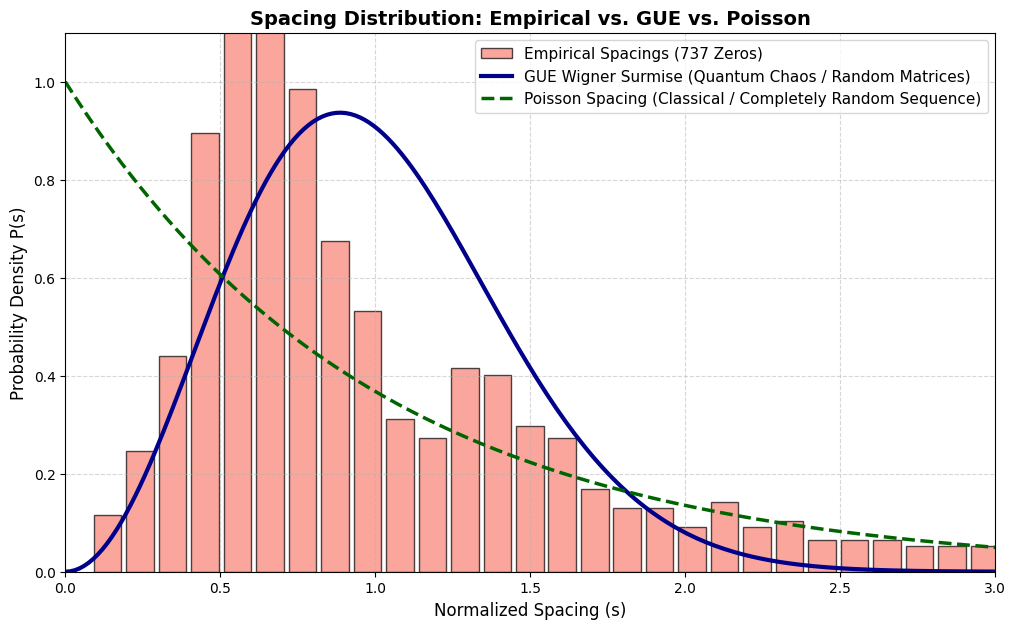

In [6]:
# Generate points for theoretical curves
s_vals = np.linspace(0, 3, 200)
p_gue = gue_wigner_surmise(s_vals)
p_poisson = np.exp(-s_vals)  # Exponential distribution with mean 1.0

# Plot the empirical vs GUE vs Poisson
plt.figure(figsize=(12, 7))

# Empirical spacings histogram
plt.hist(huge_normalized_spacings, bins=35, density=True, edgecolor='black',
         color='salmon', alpha=0.7, rwidth=0.85,
         label=f'Empirical Spacings ({len(huge_zeros_im)} Zeros)')

# GUE Wigner Surmise
plt.plot(s_vals, p_gue, color='darkblue', linewidth=3,
         label='GUE Wigner Surmise (Quantum Chaos / Random Matrices)')

# Poisson Distribution
plt.plot(s_vals, p_poisson, color='darkgreen', linestyle='--', linewidth=2.5,
         label='Poisson Spacing (Classical / Completely Random Sequence)')

plt.title("Spacing Distribution: Empirical vs. GUE vs. Poisson", fontsize=14, fontweight='bold')
plt.xlabel("Normalized Spacing (s)", fontsize=12)
plt.ylabel("Probability Density P(s)", fontsize=12)
plt.xlim(0, 3)
plt.ylim(0, 1.1)
plt.legend(fontsize=11, loc='upper right')
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2359/1921273560.py:44: SyntaxWarning: invalid escape sequence '\m'
  label=f'Normal Fit ($\mu$={mu:.3f}, $\sigma$={std:.3f})')
/tmp/ipykernel_2359/1921273560.py:44: SyntaxWarning: invalid escape sequence '\s'
  label=f'Normal Fit ($\mu$={mu:.3f}, $\sigma$={std:.3f})')


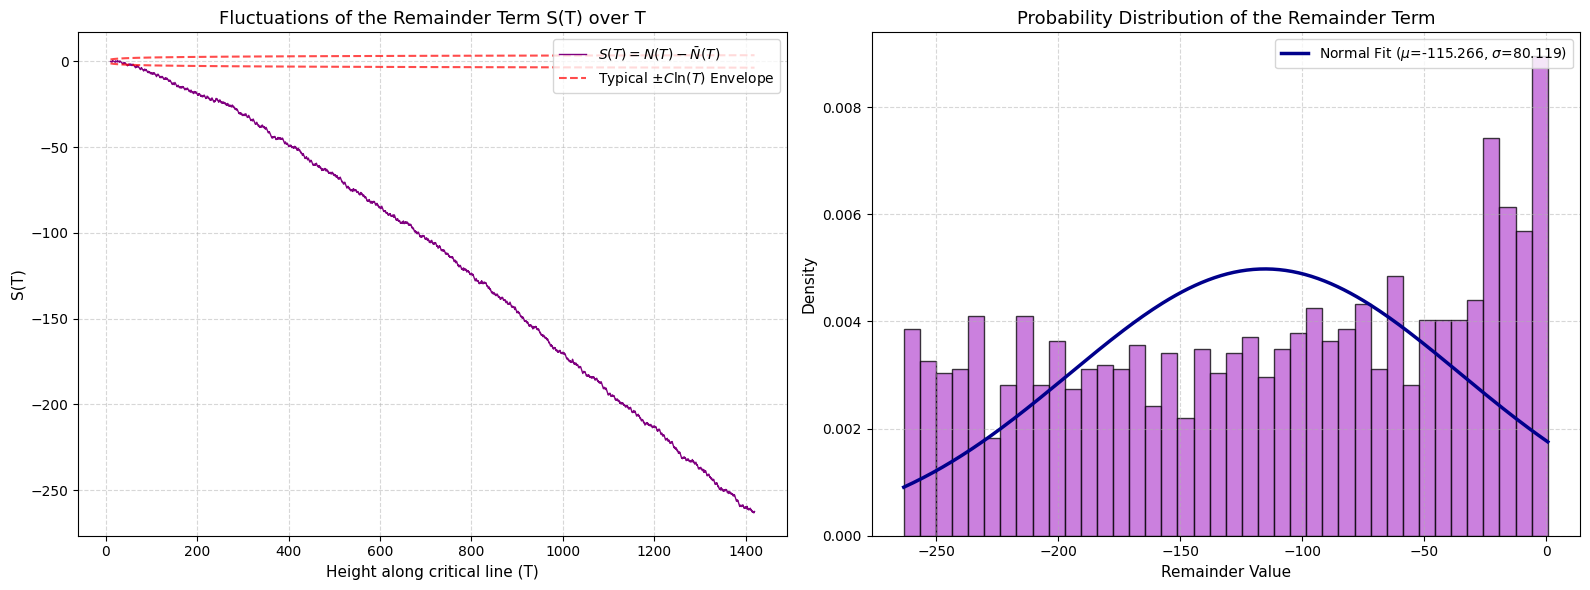

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# We will use our sorted, unique imaginary parts
t_zeros = np.array(huge_zeros_im)
T_max = t_zeros[-1]

# Create a fine grid of T values from just below the first zero to T_max
T_grid = np.linspace(10, T_max, 2000)

# Calculate exact counting function N(T) on the grid
# N(T) is the number of zeros with imaginary part <= T
N_exact = np.searchsorted(t_zeros, T_grid, side='right')

# Smooth Riemann-von Mangoldt term (including the standard 7/8 constant)
N_smooth = (T_grid / (2.0 * np.pi)) * np.log(T_grid / (2.0 * np.pi * np.e)) + 7.0/8.0

# Extract the remainder term O(log T) / S(T)
remainder = N_exact - N_smooth

# Create the visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Remainder term S(T) as a function of T
axes[0].plot(T_grid, remainder, color='purple', linewidth=1, label=r'$S(T) = N(T) - \bar{N}(T)$')
# Standard theoretical bounds are proportional to ln(T)
bound_upper = 0.5 * np.log(T_grid)
bound_lower = -0.5 * np.log(T_grid)
axes[0].plot(T_grid, bound_upper, 'r--', alpha=0.7, label=r'Typical $\pm C \ln(T)$ Envelope')
axes[0].plot(T_grid, bound_lower, 'r--', alpha=0.7)
axes[0].set_title("Fluctuations of the Remainder Term S(T) over T", fontsize=13)
axes[0].set_xlabel("Height along critical line (T)", fontsize=11)
axes[0].set_ylabel("S(T)", fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right')

# Plot 2: Histogram of the remainder values
axes[1].hist(remainder, bins=40, density=True, edgecolor='black', color='mediumorchid', alpha=0.75)
# Fit a normal distribution for visual aid
from scipy.stats import norm
mu, std = norm.fit(remainder)
x_axis = np.linspace(remainder.min(), remainder.max(), 200)
axes[1].plot(x_axis, norm.pdf(x_axis, mu, std), color='darkblue', linewidth=2.5,
             label=f'Normal Fit ($\mu$={mu:.3f}, $\sigma$={std:.3f})')
axes[1].set_title("Probability Distribution of the Remainder Term", fontsize=13)
axes[1].set_xlabel("Remainder Value", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

Calculating non-trivial zeros up to #2000 for enhanced S(T) analysis...


/tmp/ipykernel_2359/2273692929.py:7: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  sol = fsolve(zeta_complex_system, [0.5, est])
/tmp/ipykernel_2359/2273692929.py:7: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = fsolve(zeta_complex_system, [0.5, est])


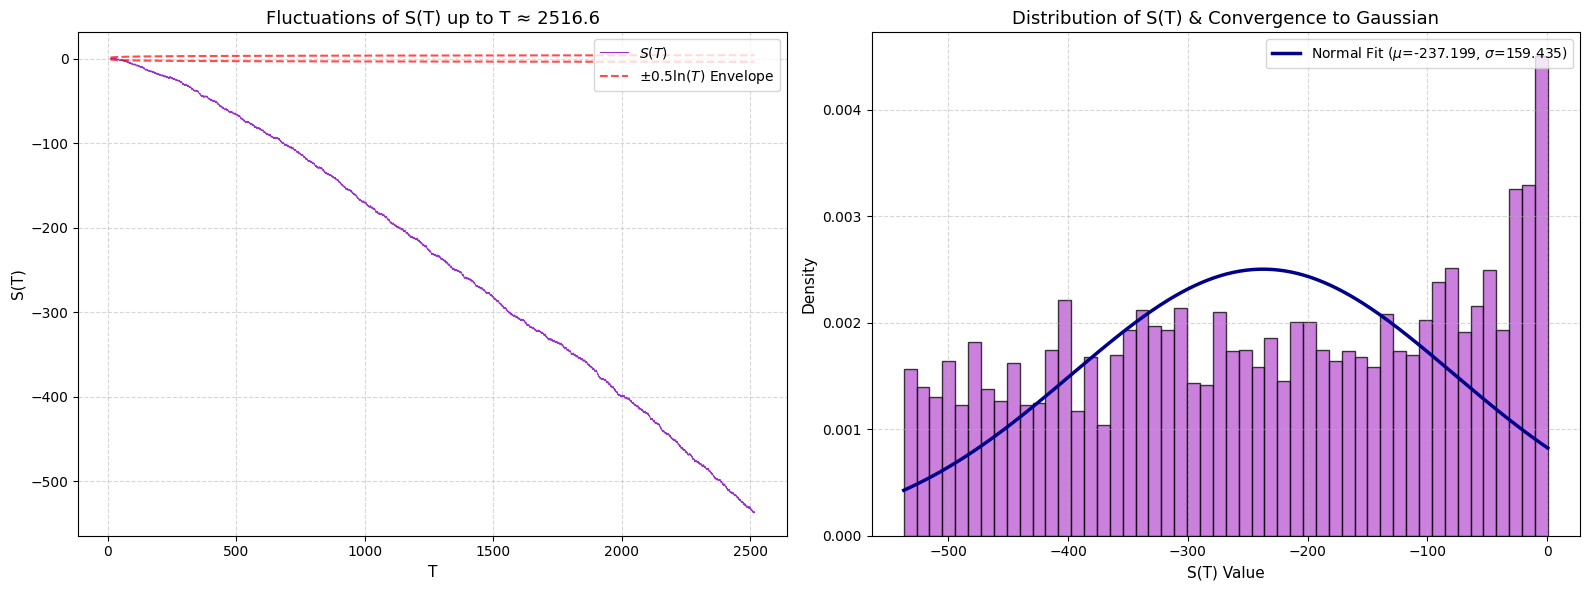

Total unique zeros in this computation: 1464


In [8]:
print("Calculating non-trivial zeros up to #2000 for enhanced S(T) analysis...")

# Extend zero-finding up to n = 2000
large_range_raw_im = []
for n in range(1, 2001):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    large_range_raw_im.append(sol[1])

# Deduplicate values within 1e-3 and sort them
large_range_zeros_im = sorted(list(set(np.round(large_range_raw_im, 3))))

# Extract grid and calculate N(T) and N_smooth(T) over this larger range
T_max_large = large_range_zeros_im[-1]
T_grid_large = np.linspace(10, T_max_large, 5000)

N_exact_large = np.searchsorted(large_range_zeros_im, T_grid_large, side='right')
N_smooth_large = (T_grid_large / (2.0 * np.pi)) * np.log(T_grid_large / (2.0 * np.pi * np.e)) + 7.0/8.0

# Calculate remainder term S(T)
remainder_large = N_exact_large - N_smooth_large

# Setup visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot S(T) over time
axes[0].plot(T_grid_large, remainder_large, color='darkorchid', linewidth=0.75, label=r'$S(T)$')
bound_upper_large = 0.5 * np.log(T_grid_large)
bound_lower_large = -0.5 * np.log(T_grid_large)
axes[0].plot(T_grid_large, bound_upper_large, 'r--', alpha=0.7, label=r'$\pm 0.5 \ln(T)$ Envelope')
axes[0].plot(T_grid_large, bound_lower_large, 'r--', alpha=0.7)
axes[0].set_title("Fluctuations of S(T) up to T ≈ " + f"{T_max_large:.1f}", fontsize=13)
axes[0].set_xlabel("T", fontsize=11)
axes[0].set_ylabel("S(T)", fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right')

# Plot distribution of S(T) with fitted Normal distribution
axes[1].hist(remainder_large, bins=50, density=True, edgecolor='black', color='mediumorchid', alpha=0.75)
from scipy.stats import norm
mu_large, std_large = norm.fit(remainder_large)
x_axis_large = np.linspace(remainder_large.min(), remainder_large.max(), 300)
axes[1].plot(x_axis_large, norm.pdf(x_axis_large, mu_large, std_large), color='darkblue', linewidth=2.5,
             label=rf'Normal Fit ($\mu$={mu_large:.3f}, $\sigma$={std_large:.3f})')
axes[1].set_title("Distribution of S(T) & Convergence to Gaussian", fontsize=13)
axes[1].set_xlabel("S(T) Value", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

print(f"Total unique zeros in this computation: {len(large_range_zeros_im)}")

--- Correlation Analysis: S(t_n) vs. Spacing s_n ---
Pearson correlation coefficient: 0.2389 (p-value: 1.991e-20)
Spearman rank correlation:       0.2365 (p-value: 4.718e-20)


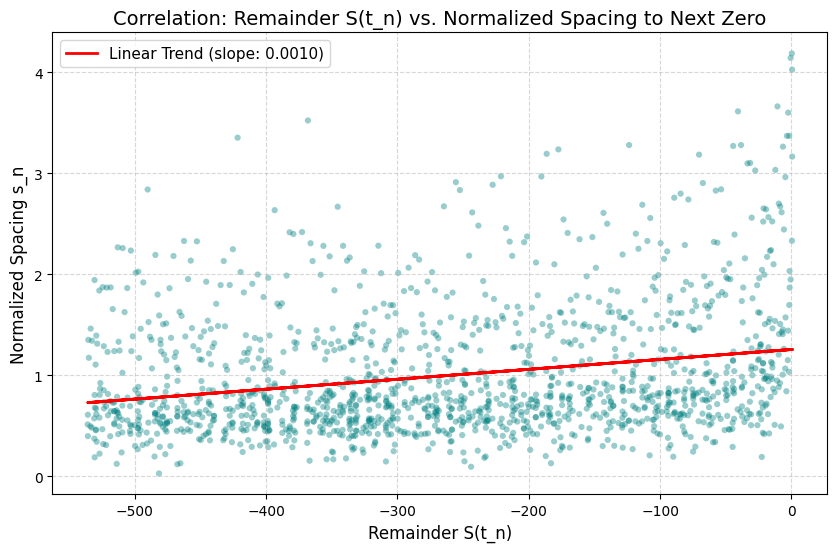

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# 1. We will use the 1464 unique zeros calculated in our large range run
t_zeros = np.array(large_range_zeros_im)

# Calculate consecutive normalized spacings associated with each zero
spacings_large = np.diff(t_zeros)
mean_spacing_large = np.mean(spacings_large)
normalized_spacings_large = spacings_large / mean_spacing_large

# 2. For each zero t_n (excluding the last one since we need spacing to t_{n+1}),
# calculate the smooth estimate N_smooth(t_n) and exact index count n
t_zeros_subset = t_zeros[:-1]

# Exact count just before/at the zero. Since t_zeros are the exact roots,
# the exact count jumps precisely at t_n. We can use the index 'n' (1-based) as N_exact
n_exact = np.arange(1, len(t_zeros_subset) + 1)

# Smooth Riemann-von Mangoldt term at the exact zero coordinates
n_smooth = (t_zeros_subset / (2.0 * np.pi)) * np.log(t_zeros_subset / (2.0 * np.pi * np.e)) + 7.0/8.0

# Remainder S(t_n) at each zero
s_at_zeros = n_exact - n_smooth

# 3. Calculate statistical correlation between S(t_n) and the normalized spacing to the next zero
pearson_corr, p_pearson = pearsonr(s_at_zeros, normalized_spacings_large)
spearman_corr, p_spearman = spearmanr(s_at_zeros, normalized_spacings_large)

print("--- Correlation Analysis: S(t_n) vs. Spacing s_n ---")
print(f"Pearson correlation coefficient: {pearson_corr:.4f} (p-value: {p_pearson:.3e})")
print(f"Spearman rank correlation:       {spearman_corr:.4f} (p-value: {p_spearman:.3e})")

# 4. Visualization of the relationship
plt.figure(figsize=(10, 6))
plt.scatter(s_at_zeros, normalized_spacings_large, alpha=0.4, color='teal', edgecolor='none', s=20)

# Add a trendline
m, b = np.polyfit(s_at_zeros, normalized_spacings_large, 1)
plt.plot(s_at_zeros, m * s_at_zeros + b, color='red', linewidth=2, label=f'Linear Trend (slope: {m:.4f})')

plt.title("Correlation: Remainder S(t_n) vs. Normalized Spacing to Next Zero", fontsize=14)
plt.xlabel("Remainder S(t_n)", fontsize=12)
plt.ylabel("Normalized Spacing s_n", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()


Calculating non-trivial zeros up to #4000 for a large-scale statistical correlation analysis...


/tmp/ipykernel_2359/4196166555.py:12: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  sol = fsolve(zeta_complex_system, [0.5, est])
/tmp/ipykernel_2359/4196166555.py:12: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = fsolve(zeta_complex_system, [0.5, est])


Found 2939 unique non-trivial zeros up to T ≈ 4507.74.

--- Large-Scale Correlation Analysis (N = 2939) ---
Pearson correlation coefficient: 0.23778 (p-value: 4.828e-39)
Spearman rank correlation:       0.23558 (p-value: 2.467e-38)


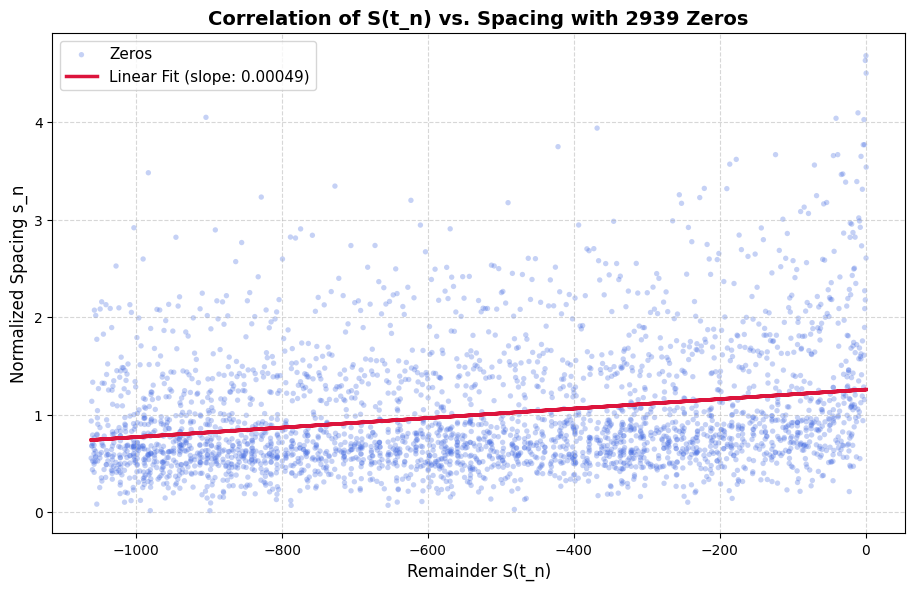

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from scipy.optimize import fsolve

print("Calculating non-trivial zeros up to #4000 for a large-scale statistical correlation analysis...")

# 1. Zero finding up to n = 4000
super_large_raw_im = []
for n in range(1, 4001):
    est = estimate_gamma_robust(n)
    sol = fsolve(zeta_complex_system, [0.5, est])
    super_large_raw_im.append(sol[1])

# Deduplicate and sort
super_large_zeros = np.array(sorted(list(set(np.round(super_large_raw_im, 3)))))
num_zeros = len(super_large_zeros)
print(f"Found {num_zeros} unique non-trivial zeros up to T ≈ {super_large_zeros[-1]:.2f}.")

# 2. Spacing computation
spacings_super = np.diff(super_large_zeros)
mean_spacing_super = np.mean(spacings_super)
normalized_spacings_super = spacings_super / mean_spacing_super

# 3. Compute S(t_n) at each zero (excluding the last one)
t_subset = super_large_zeros[:-1]
n_exact_super = np.arange(1, len(t_subset) + 1)
n_smooth_super = (t_subset / (2.0 * np.pi)) * np.log(t_subset / (2.0 * np.pi * np.e)) + 7.0/8.0
s_values_super = n_exact_super - n_smooth_super

# 4. Correlation metrics
pearson_corr_super, p_pearson_super = pearsonr(s_values_super, normalized_spacings_super)
spearman_corr_super, p_spearman_super = spearmanr(s_values_super, normalized_spacings_super)

print("\n--- Large-Scale Correlation Analysis (N = " + str(num_zeros) + ") ---")
print(f"Pearson correlation coefficient: {pearson_corr_super:.5f} (p-value: {p_pearson_super:.3e})")
print(f"Spearman rank correlation:       {spearman_corr_super:.5f} (p-value: {p_spearman_super:.3e})")

# 5. Scatter Plot and Linear Trend
plt.figure(figsize=(11, 6.5))
plt.scatter(s_values_super, normalized_spacings_super, alpha=0.3, color='royalblue', edgecolor='none', s=15, label='Zeros')

m_super, b_super = np.polyfit(s_values_super, normalized_spacings_super, 1)
plt.plot(s_values_super, m_super * s_values_super + b_super, color='crimson', linewidth=2.5,
         label=f'Linear Fit (slope: {m_super:.5f})')

plt.title(f"Correlation of S(t_n) vs. Spacing with {num_zeros} Zeros", fontsize=14, fontweight='bold')
plt.xlabel("Remainder S(t_n)", fontsize=12)
plt.ylabel("Normalized Spacing s_n", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')
plt.show()


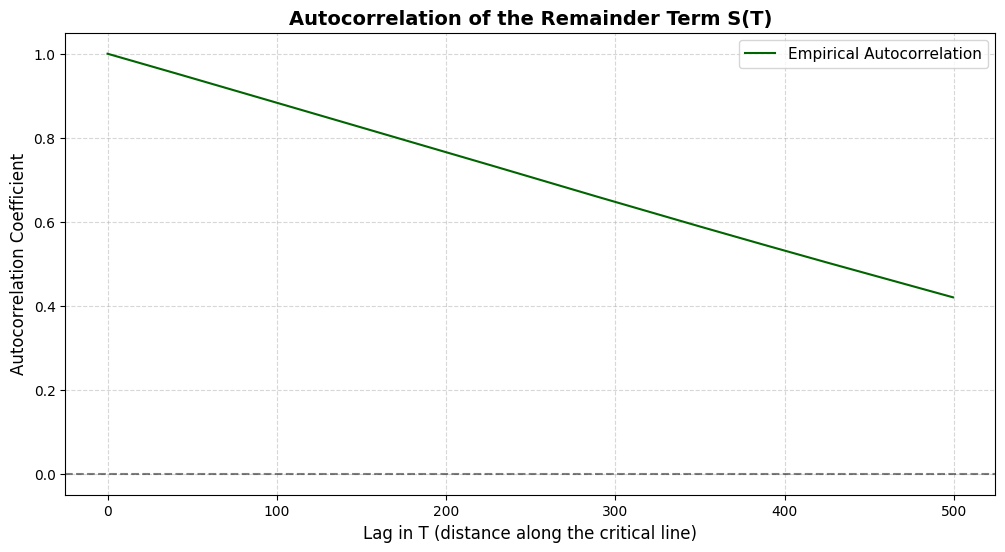

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# We will use the remainder_large sequence calculated over T_grid_large from cell c02f811e
# Let's subtract the mean of the remainder to compute a proper autocovariance / autocorrelation
remainder_centered = remainder_large - np.mean(remainder_large)

# Compute autocorrelation using numpy's correlate
# Normalizing by variance and length to get a standard correlation sequence from -1 to 1
n_points = len(remainder_centered)
variance = np.var(remainder_centered)

# Compute full cross-correlation and slice the second half (positive lags)
full_corr = np.correlate(remainder_centered, remainder_centered, mode='full')
autocorr = full_corr[full_corr.size // 2:] / (variance * n_points)

# Define the corresponding lag values in terms of grid indices and physical T coordinates
lags = np.arange(len(autocorr))
# Map lag index to actual change in T
dt = T_grid_large[1] - T_grid_large[0]
physical_lags = lags * dt

# Limit the plot to a reasonable range (e.g., lag of up to T = 500) to see fine details
max_plot_lag = int(500 / dt)

plt.figure(figsize=(12, 6))
plt.plot(physical_lags[:max_plot_lag], autocorr[:max_plot_lag], color='darkgreen', linewidth=1.5, label='Empirical Autocorrelation')
plt.axhline(0, color='black', linestyle='--', alpha=0.5)

plt.title("Autocorrelation of the Remainder Term S(T)", fontsize=14, fontweight='bold')
plt.xlabel("Lag in T (distance along the critical line)", fontsize=12)
plt.ylabel("Autocorrelation Coefficient", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()


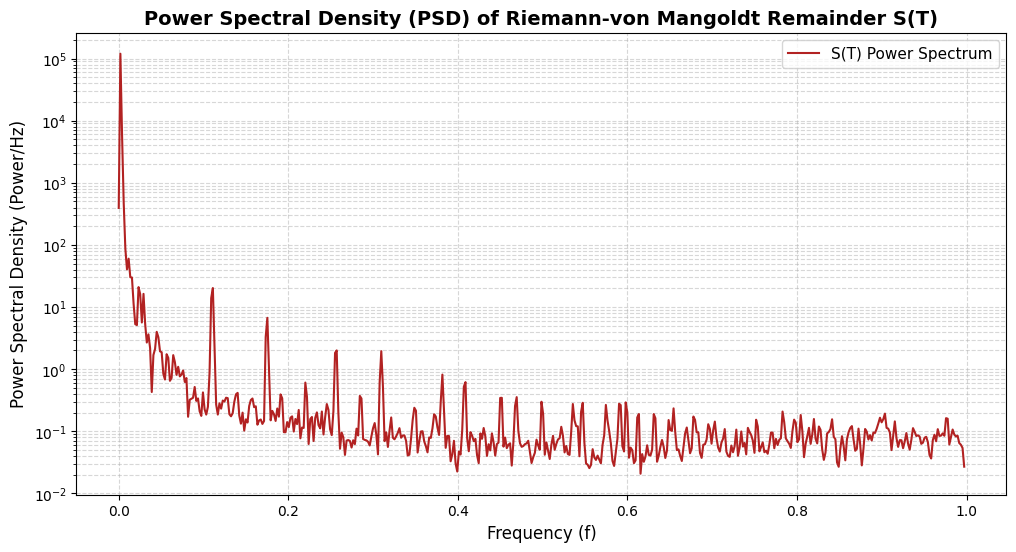

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# We use the centered large-scale remainder term S(T)
# S(T) is evaluated on T_grid_large
dt = T_grid_large[1] - T_grid_large[0]
fs = 1.0 / dt  # Sampling frequency

# Compute Power Spectral Density (PSD) using Welch's method
frequencies, psd = welch(remainder_centered, fs=fs, nperseg=1024)

# Plot the Power Spectral Density
plt.figure(figsize=(12, 6))
plt.semilogy(frequencies, psd, color='firebrick', linewidth=1.5, label='S(T) Power Spectrum')

plt.title("Power Spectral Density (PSD) of Riemann-von Mangoldt Remainder S(T)", fontsize=14, fontweight='bold')
plt.xlabel("Frequency (f)", fontsize=12)
plt.ylabel("Power Spectral Density (Power/Hz)", fontsize=12)
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()
